In [18]:
# ============================================================
# LSTM SENTIMENT ANALYSIS
# Student Roll No: 24BAD077
# PART A: DATASET PREPARATION AND TEXT PREPROCESSING
# ============================================================

import numpy as np
import pandas as pd
import re
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("Student Roll No: 24BAD077")
print("TensorFlow Version:", tf.__version__)

Student Roll No: 24BAD077
TensorFlow Version: 2.20.0


In [19]:
# Download IMDB dataset
url = "https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"

dataset_path = tf.keras.utils.get_file(
    "aclImdb_v1.tar.gz",
    url,
    untar=True
)

print("IMDB dataset downloaded successfully!")
print(dataset_path)

IMDB dataset downloaded successfully!
/root/.keras/datasets/aclImdb_v1_extracted


In [20]:
# ============================================================
# STEP 3: FIND AND LOAD THE IMDB DATASET
# Student Roll No: 24BAD077
# ============================================================
import os
# Check what was actually downloaded
base_path = "/root/.keras/datasets"
print("Files/Folders available:")
print(os.listdir(base_path))
# Find the aclImdb folder automatically
dataset_dir = None
for item in os.listdir(base_path):
    possible_path = os.path.join(base_path, item)
    if os.path.isdir(possible_path) and item.lower() == "aclimdb":
        dataset_dir = possible_path
        break
print("\nDataset directory:", dataset_dir)
# Check the dataset structure
if dataset_dir:
    print("\nDataset contents:")
    print(os.listdir(dataset_dir))
    print("\nTrain folder:")
    print(os.listdir(os.path.join(dataset_dir, "train")))
    print("\nTest folder:")
    print(os.listdir(os.path.join(dataset_dir, "test")))
else:
    print("IMDB dataset folder was not found.")

Files/Folders available:
['aclImdb_v1_extracted', 'aclImdb_v1.tar.gz']

Dataset directory: None
IMDB dataset folder was not found.


In [21]:
# FIX DATASET PATH AND LOAD IMDB REVIEWS
# Student Roll No: 24BAD077
import os
dataset_dir = "/root/.keras/datasets/aclImdb_v1_extracted/aclImdb"
print("Dataset directory:")
print(dataset_dir)
print("\nDataset contents:")
print(os.listdir(dataset_dir))
# Function to load reviews
def load_reviews(folder):
    reviews = []
    labels = []
    folder_path = os.path.join(dataset_dir, folder)
    for sentiment in ["pos", "neg"]:
        sentiment_path = os.path.join(
            folder_path,
            sentiment
        )
        for filename in os.listdir(sentiment_path):
            if filename.endswith(".txt"):
                file_path = os.path.join(
                    sentiment_path,
                    filename
                )
                with open(
                    file_path,
                    "r",
                    encoding="utf-8"
                ) as f:
                    reviews.append(f.read())
                # Positive = 1
                # Negative = 0
                if sentiment == "pos":
                    labels.append(1)
                else:
                    labels.append(0)
    return reviews, labels
# Load train and test reviews
train_reviews, train_labels = load_reviews("train")
test_reviews, test_labels = load_reviews("test")
reviews = train_reviews + test_reviews
labels = train_labels + test_labels
print("\n========================================")
print("IMDB DATASET LOADED SUCCESSFULLY")
print("========================================")
print("Training reviews :", len(train_reviews))
print("Testing reviews  :", len(test_reviews))
print("Total reviews    :", len(reviews))
print("Total labels     :", len(labels))

Dataset directory:
/root/.keras/datasets/aclImdb_v1_extracted/aclImdb

Dataset contents:
['imdb.vocab', 'train', 'imdbEr.txt', 'README', 'test']

IMDB DATASET LOADED SUCCESSFULLY
Training reviews : 25000
Testing reviews  : 25000
Total reviews    : 50000
Total labels     : 50000


In [22]:
print("Student Roll No: 24BAD077")
print("\n===== SAMPLE POSITIVE REVIEW =====")
print(train_reviews[0][:1000])
print("\n===== SAMPLE NEGATIVE REVIEW =====")
print(train_reviews[-1][:1000])
print("\n===== LABEL INFORMATION =====")
print("0 = Negative")
print("1 = Positive")

Student Roll No: 24BAD077

===== SAMPLE POSITIVE REVIEW =====
Will Smith delivers yet again in a film about a man with the weight of the world on his shoulders and his crusade to right his wrongs in a way that will touch even the most hardened of hearts!!! Writer Grant Nieporte and Italian Director Gabriele Muccino come together and created a masterpiece that I highly recommend to purchase and keep in your movie collection as you will never grow tired of watching/feeling this film!!! I have the Highest Respects for Will Smith as he is not only a brilliant Actor but one can tell he has a genuine love for people and life which no doubt made him perfect for the character (IRS Agent Ben Thomas) he played in this film. You will find yourself feeling his pain and anger, the frustrations over his love for Emily, played by Rosario Dawson, who by the way was Fantastic as usual. I found myself falling in love with the fact their characters were falling in love. Woody Harrelson also stars in this

In [23]:
# STEP 5: CHECK CLASS DISTRIBUTION
import pandas as pd
data = pd.DataFrame({
    "review": reviews,
    "sentiment": labels
})
print("Total number of reviews:", len(data))
print("\nSentiment Distribution:")
print(data["sentiment"].value_counts())
print("\nPercentage Distribution:")
print(data["sentiment"].value_counts(normalize=True) * 100)

Total number of reviews: 50000

Sentiment Distribution:
sentiment
1    25000
0    25000
Name: count, dtype: int64

Percentage Distribution:
sentiment
1    50.0
0    50.0
Name: proportion, dtype: float64


In [24]:
# STEP 6: TEXT PREPROCESSING
import re
def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()
    # Remove HTML t
    text = re.sub(r"<br\s*/?>", " ", text)
    # Remove punctuation and special charaers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    return text
# Apply preprocessing
data["cleaned_review"] = data["review"].apply(preprocess_text)
# Display before and after preprocessing
print("===== ORIGINAL REVIEW =====")
print(data["review"].iloc[0][:500])
print("\n===== CLEANED REVIEW =====")
print(data["cleaned_review"].iloc[0][:500])

===== ORIGINAL REVIEW =====
Will Smith delivers yet again in a film about a man with the weight of the world on his shoulders and his crusade to right his wrongs in a way that will touch even the most hardened of hearts!!! Writer Grant Nieporte and Italian Director Gabriele Muccino come together and created a masterpiece that I highly recommend to purchase and keep in your movie collection as you will never grow tired of watching/feeling this film!!! I have the Highest Respects for Will Smith as he is not only a brilliant 

===== CLEANED REVIEW =====
will smith delivers yet again in a film about a man with the weight of the world on his shoulders and his crusade to right his wrongs in a way that will touch even the most hardened of hearts writer grant nieporte and italian director gabriele muccino come together and created a masterpiece that i highly recommend to purchase and keep in your movie collection as you will never grow tired of watching feeling this film i have the highest res

In [25]:
# ============================================================
# STEP 7: DATASET SPLITTING
# ============================================================
from sklearn.model_selection import train_test_split
X = data["cleaned_review"].values
y = data["sentiment"].values
# 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
# Split remaining 20% equally:
# 10% validation + 10% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)
print("===== DATASET SPLIT =====")
print("Training samples   :", len(X_train))
print("Validation samples :", len(X_val))
print("Testing samples    :", len(X_test))

===== DATASET SPLIT =====
Training samples   : 40000
Validation samples : 5000
Testing samples    : 5000


In [26]:
# ============================================================
# STEP 8: TOKENIZATION
# ============================================================

from tensorflow.keras.preprocessing.text import Tokenizer

vocab_size = 10000

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

# IMPORTANT:
# Build vocabulary ONLY using training data
tokenizer.fit_on_texts(X_train)

print("===== TOKENIZATION =====")
print("Vocabulary created successfully!")
print("Total words found:", len(tokenizer.word_index))

print("\nFirst 20 words in vocabulary:")
print(list(tokenizer.word_index.items())[:20])

===== TOKENIZATION =====
Vocabulary created successfully!
Total words found: 90876

First 20 words in vocabulary:
[('<OOV>', 1), ('the', 2), ('and', 3), ('a', 4), ('of', 5), ('to', 6), ('is', 7), ('it', 8), ('in', 9), ('i', 10), ('this', 11), ('that', 12), ('s', 13), ('was', 14), ('as', 15), ('movie', 16), ('with', 17), ('for', 18), ('but', 19), ('film', 20)]


In [27]:
# ============================================================
# STEP 9: TEXT TO NUMERICAL SEQUENCES
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)
print("===== NUMERICAL SEQUENCES =====")
print("\nOriginal text:")
print(X_train[0][:300])
print("\nNumerical sequence:")
print(X_train_seq[0][:50])

===== NUMERICAL SEQUENCES =====

Original text:
this is one of the greatest films ever made brilliant acting by george c scott and diane riggs this movie is both disturbing and extremely deep don t be fooled into believing this is just a comedy it is a brilliant satire about the medical profession it is not a pretty picture healthy patients are k

Numerical sequence:
[11, 7, 29, 5, 2, 804, 104, 124, 92, 499, 114, 34, 700, 940, 1027, 3, 3068, 1, 11, 16, 7, 196, 1189, 3, 560, 843, 90, 22, 30, 4242, 84, 3591, 11, 7, 42, 4, 199, 8, 7, 4, 499, 1941, 45, 2, 2770, 5465, 8, 7, 24, 4]


In [28]:
# ============================================================
# STEP 10: SEQUENCE PADDING
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_length = 200
X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)
X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)
X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)
print("===== AFTER PADDING =====")
print("Training shape   :", X_train_pad.shape)
print("Validation shape :", X_val_pad.shape)
print("Testing shape    :", X_test_pad.shape)


===== AFTER PADDING =====
Training shape   : (40000, 200)
Validation shape : (5000, 200)
Testing shape    : (5000, 200)


In [29]:
# ============================================================
# STEP 11: FINAL DATASET SUMMARY
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)
print("==============================================")
print("       PART A - FINAL DATASET SUMMARY")
print("       Student Roll No: 24BAD077")
print("==============================================")
print("\nVocabulary size :", vocab_size)
print("Maximum sequence length :", max_length)
print("\nTraining data:")
print("X_train :", X_train_pad.shape)
print("y_train :", y_train.shape)
print("\nValidation data:")
print("X_val   :", X_val_pad.shape)
print("y_val   :", y_val.shape)
print("\nTesting data:")
print("X_test  :", X_test_pad.shape)
print("y_test  :", y_test.shape)
print("\nPreprocessing completed successfully!")

       PART A - FINAL DATASET SUMMARY
       Student Roll No: 24BAD077

Vocabulary size : 10000
Maximum sequence length : 200

Training data:
X_train : (40000, 200)
y_train : (40000,)

Validation data:
X_val   : (5000, 200)
y_val   : (5000,)

Testing data:
X_test  : (5000, 200)
y_test  : (5000,)

Preprocessing completed successfully!


In [30]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Embedding
print("       PART B - EMBEDDING GENERATION")
print("       Student Roll No: 24BAD077")
# 1. Define vocabulary size and embedding dimension
vocab_size = 10000
embedding_dim = 128
max_length = 200
print("\nVocabulary Size:", vocab_size)
print("Embedding Dimension:", embedding_dim)
print("Maximum Sequence Length:", max_length)
# 2. Create the Embedding Layer
embedding_layer = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim
)
print("\nEmbedding layer created successfully!")
# ------------------------------------------------------------
# 3. Select sample padded sequences
# ------------------------------------------------------------
sample_input = X_train_pad[:10]
print("\nInput sequence shape:")
print(sample_input.shape)
# ------------------------------------------------------------
# 4. Generate Embedding Representations
# ------------------------------------------------------------
embedded_output = embedding_layer(sample_input)
print("\nEmbedding output shape:")
print(embedded_output.shape)
# ------------------------------------------------------------
# 5. Display one word/token embedding
# ------------------------------------------------------------
first_word_vector = embedded_output[0, 1]
print("\nEmbedding vector of one token:")
print(first_word_vector.numpy())
print("\nShape of one word embedding:")
print(first_word_vector.shape)
# ------------------------------------------------------------
# 6. Display Embedding Layer Weight Shape
# ------------------------------------------------------------
embedding_weights = embedding_layer.get_weights()[0]
print("\nEmbedding layer weights shape:")
print(embedding_weights.shape)
# ------------------------------------------------------------
# 7. Final Analysis
# ------------------------------------------------------------
print("\n==============================================")
print("             EMBEDDING ANALYSIS")
print("==============================================")
print("Each token is represented using", embedding_dim, "numerical values.")
print("Input shape:", sample_input.shape)
print("Embedding output shape:", embedded_output.shape)
print("Embedding weights shape:", embedding_weights.shape)
print("\nPart B completed successfully!")

       PART B - EMBEDDING GENERATION
       Student Roll No: 24BAD077

Vocabulary Size: 10000
Embedding Dimension: 128
Maximum Sequence Length: 200

Embedding layer created successfully!

Input sequence shape:
(10, 200)

Embedding output shape:
(10, 200, 128)

Embedding vector of one token:
[-0.04114892 -0.03933214 -0.03075097  0.00033542 -0.02319026  0.02113333
 -0.03771778 -0.00143002  0.01257951  0.01826838  0.04197067 -0.04682226
 -0.01741467 -0.00875832  0.03499171 -0.03833082 -0.02722245  0.02554539
 -0.04612621 -0.00275438  0.02473107  0.00952359  0.01152511  0.0361974
 -0.02756425  0.02040813 -0.00647408  0.01961822  0.01919011  0.03218644
  0.02760928  0.02367801 -0.00460601  0.02107351 -0.01924292  0.00707776
 -0.02166315 -0.03596246  0.04740227  0.0272789  -0.02527256  0.04812132
  0.00182924 -0.01224549 -0.00197704 -0.01855072 -0.02339875  0.04023382
 -0.0169366   0.0403782   0.0113755  -0.03873273  0.02589354 -0.03052051
  0.01748848  0.03212317 -0.04860295  0.01072688 -0.

In [31]:
# PART C: IMPLEMENTING THE LSTM MODEL
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
print("       PART C - LSTM MODEL")
vocab_size = 10000
embedding_dim = 128
max_length = 200
lstm_units = 64
print("\nMODEL PARAMETERS")
print("----------------------------------------------")
print("Vocabulary Size       :", vocab_size)
print("Embedding Dimension   :", embedding_dim)
print("Maximum Sequence Length:", max_length)
print("LSTM Units            :", lstm_units)
model = Sequential([
    Input(shape=(max_length,))
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    ),
    LSTM(lstm_units),
    Dense(1, activation="sigmoid")
])
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
print("\n==============================================")
print("           MODEL ARCHITECTURE")
print("==============================================")
model.summary()
print("Optimizer          : Adam")
print("Loss Function      : Binary Cross-Entropy")
print("Evaluation Metric  : Accuracy")
print("Output Activation  : Sigmoid")
print("0 → Negative Sentiment")
print("1 → Positive Sentiment")

       PART C - LSTM MODEL
       Student Roll No: 24BAD077

MODEL PARAMETERS
----------------------------------------------
Vocabulary Size       : 10000
Embedding Dimension   : 128
Maximum Sequence Length: 200
LSTM Units            : 64

           MODEL ARCHITECTURE


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,329,473 (5.07 MB)

 Trainable params: 1,329,473 (5.07 MB)

 Non-trainable params: 0 (0.00 B)


          EVALUATION CONFIGURATION
Optimizer          : Adam
Loss Function      : Binary Cross-Entropy
Evaluation Metric  : Accuracy
Output Activation  : Sigmoid

             CLASSIFICATION
0 → Negative Sentiment
1 → Positive Sentiment

        PART C COMPLETED SUCCESSFULLY


       PART D - TRAINING & EVALUATION
       Student Roll No: 24BAD077

Dataset used for faster training:
Training   : (10000, 200)
Validation : (2000, 200)
Testing    : (2000, 200)

Model created successfully.

             MODEL TRAINING
Epoch 1/2
79/79 ━━━━━━━━━━━━━━━━━━━━ 34s 396ms/step - accuracy: 0.5215 - loss: 0.6918 - val_accuracy: 0.5855 - val_loss: 0.7055
Epoch 2/2
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 392ms/step - accuracy: 0.5805 - loss: 0.6777 - val_accuracy: 0.5405 - val_loss: 0.6780

Training completed successfully!

       TRAINING & VALIDATION RESULTS
Epoch 1: Train Accuracy = 0.5215, Validation Accuracy = 0.5855, Train Loss = 0.6918, Validation Loss = 0.7055
Epoch 2: Train Accuracy = 0.5805, Validation Accuracy = 0.5405, Train Loss = 0.6777, Validation Loss = 0.6780

Final Training Accuracy   : 0.5805
Final Validation Accuracy : 0.5405
Final Training Loss       : 0.6777
Final Validation Loss     : 0.6780


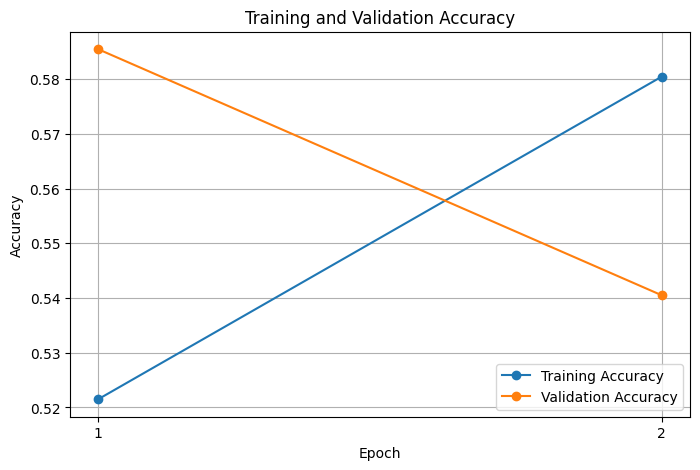

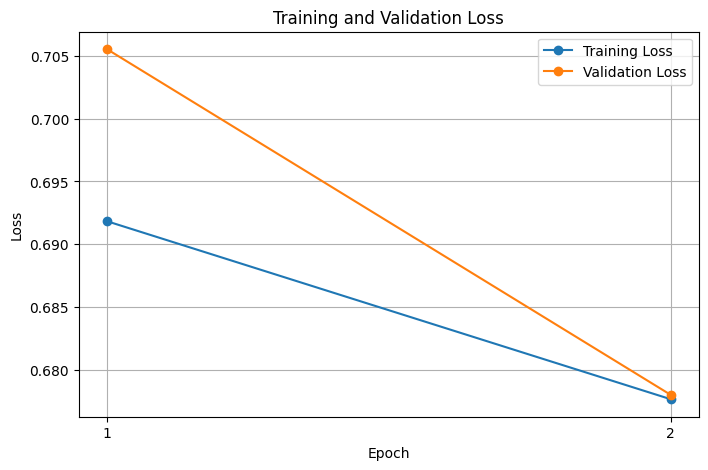


             TEST SET EVALUATION
Test Loss     : 0.6815
Test Accuracy : 0.5255

          GENERATING PREDICTIONS
Predictions generated successfully.

          ACTUAL VS PREDICTED

Sample | Actual | Predicted | Probability
----------------------------------------------
     1 |      0 |         0 | 0.4663
     2 |      1 |         0 | 0.4763
     3 |      1 |         1 | 0.5228
     4 |      0 |         0 | 0.4778
     5 |      0 |         1 | 0.5075
     6 |      0 |         0 | 0.4763
     7 |      0 |         0 | 0.4763
     8 |      0 |         0 | 0.4759
     9 |      1 |         1 | 0.6069
    10 |      0 |         0 | 0.4762

          CLASSIFICATION METRICS
Accuracy  : 0.5255
Precision : 0.5597
Recall    : 0.3814
F1-Score  : 0.4537

          CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Negative       0.51      0.68      0.58       967
    Positive       0.56      0.38      0.45      1033

    accuracy                           0.53      200

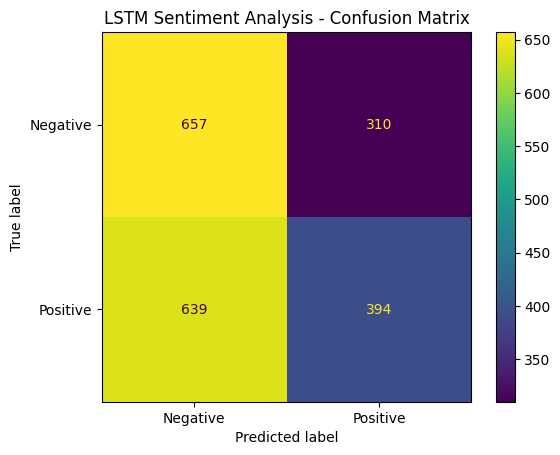


          SAMPLE REVIEW PREDICTIONS

Review     : This movie was absolutely wonderful and amazing.
Sentiment  : Negative
Probability: 0.4763

Review     : The movie was boring and I did not enjoy it.
Sentiment  : Negative
Probability: 0.4763

Review     : Excellent acting and a fantastic story.
Sentiment  : Negative
Probability: 0.4763

Review     : The film was terrible and disappointing.
Sentiment  : Negative
Probability: 0.4763

       PART D COMPLETED SUCCESSFULLY

Test Accuracy : 0.5255
Precision     : 0.5597
Recall        : 0.3814
F1-Score      : 0.4537


In [32]:
# PART D: TRAINING AND EVALUATION
# LSTM SENTIMENT ANALYSIS
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
train_samples = 10000
val_samples = 2000
test_samples = 2000
X_train_small = X_train_pad[:train_samples]
y_train_small = y_train[:train_samples]
X_val_small = X_val_pad[:val_samples]
y_val_small = y_val[:val_samples]
X_test_small = X_test_pad[:test_samples]
y_test_small = y_test[:test_samples]
print("\nDataset used for faster training:")
print("Training   :", X_train_small.shape)
print("Validation :", X_val_small.shape)
print("Testing    :", X_test_small.shape)
# 2. RECREATE MODEL
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
vocab_size = 10000
embedding_dim = 128
max_length = 200
lstm_units = 64
model = Sequential([
    Input(shape=(max_length,)),
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    ),
    LSTM(lstm_units),
    Dense(1, activation="sigmoid")
])
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
print("\nModel created successfully.")
print("             MODEL TRAINING")
epochs = 2
batch_size = 128
history = model.fit(
    X_train_small,
    y_train_small,
    validation_data=(X_val_small, y_val_small),
    epochs=epochs,
    batch_size=batch_size,
    verbose=1
)
print("\nTraining completed successfully!")
train_accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
print("\n==============================================")
print("       TRAINING & VALIDATION RESULTS")
print("==============================================")
for i in range(epochs):
    print(
        f"Epoch {i+1}: "
        f"Train Accuracy = {train_accuracy[i]:.4f}, "
        f"Validation Accuracy = {val_accuracy[i]:.4f}, "
        f"Train Loss = {train_loss[i]:.4f}, "
        f"Validation Loss = {val_loss[i]:.4f}"
    )
print("\nFinal Training Accuracy   :", f"{train_accuracy[-1]:.4f}")
print("Final Validation Accuracy :", f"{val_accuracy[-1]:.4f}")
print("Final Training Loss       :", f"{train_loss[-1]:.4f}")
print("Final Validation Loss     :", f"{val_loss[-1]:.4f}")
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, epochs + 1),
    train_accuracy,
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    range(1, epochs + 1),
    val_accuracy,
    marker="o",
    label="Validation Accuracy"
)
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.show()
# ============================================================
# 6. LOSS GRAPH
# ============================================================
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, epochs + 1),
    train_loss,
    marker="o",
    label="Training Loss"
)
plt.plot(
    range(1, epochs + 1),
    val_loss,
    marker="o",
    label="Validation Loss"
)
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.show()
print("\n==============================================")
print("             TEST SET EVALUATION")
print("==============================================")
test_loss, test_accuracy = model.evaluate(
    X_test_small,
    y_test_small,
    verbose=0
)
print("Test Loss     :", f"{test_loss:.4f}")
print("Test Accuracy :", f"{test_accuracy:.4f}")
print("\n==============================================")
print("          GENERATING PREDICTIONS")
print("==============================================")
y_probability = model.predict(
    X_test_small,
    batch_size=batch_size,
    verbose=0
).ravel()
y_pred = (y_probability >= 0.5).astype(int)
print("Predictions generated successfully.")
print("\n==============================================")
print("          ACTUAL VS PREDICTED")
print("==============================================")
print("\nSample | Actual | Predicted | Probability")
print("----------------------------------------------")
for i in range(10):
    print(
        f"{i+1:6d} | "
        f"{int(y_test_small[i]):6d} | "
        f"{int(y_pred[i]):9d} | "
        f"{y_probability[i]:.4f}"
    )
accuracy = accuracy_score(y_test_small, y_pred)
precision = precision_score(
    y_test_small,
    y_pred,
    zero_division=0
)
recall = recall_score(
    y_test_small,
    y_pred,
    zero_division=0
)
f1 = f1_score(
    y_test_small,
    y_pred,
    zero_division=0
)
print("\n==============================================")
print("          CLASSIFICATION METRICS")
print("==============================================")
print("Accuracy  :", f"{accuracy:.4f}")
print("Precision :", f"{precision:.4f}")
print("Recall    :", f"{recall:.4f}")
print("F1-Score  :", f"{f1:.4f}")
print("\n==============================================")
print("          CLASSIFICATION REPORT")
print("==============================================")
print(
    classification_report(
        y_test_small,
        y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)
print("\n==============================================")
print("             CONFUSION MATRIX")
print("==============================================")
cm = confusion_matrix(y_test_small, y_pred)
print(cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)
disp.plot()
plt.title("LSTM Sentiment Analysis - Confusion Matrix")
plt.show()
print("\n==============================================")
print("          SAMPLE REVIEW PREDICTIONS")
print("==============================================")
sample_reviews = [
    "This movie was absolutely wonderful and amazing.",
    "The movie was boring and I did not enjoy it.",
    "Excellent acting and a fantastic story.",
    "The film was terrible and disappointing."
]
sample_cleaned = [
    preprocess_text(review)
    for review in sample_reviews
]
sample_sequences = tokenizer.texts_to_sequences(sample_cleaned)
sample_padded = tf.keras.preprocessing.sequence.pad_sequences(
    sample_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)
sample_probabilities = model.predict(
    sample_padded,
    verbose=0
).ravel()
for review, probability in zip(
    sample_reviews,
    sample_probabilities
):

    sentiment = "Positive" if probability >= 0.5 else "Negative"
    print("\nReview     :", review)
    print("Sentiment  :", sentiment)
    print("Probability:", f"{probability:.4f}")
print("\n==============================================")
print("       PART D COMPLETED SUCCESSFULLY")
print("==============================================")

print("\nTest Accuracy :", f"{test_accuracy:.4f}")
print("Precision     :", f"{precision:.4f}")
print("Recall        :", f"{recall:.4f}")
print("F1-Score      :", f"{f1:.4f}")